In [1]:
from typing import TypedDict, Annotated
from dotenv import load_dotenv
import requests
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langchain_openai import ChatOpenAI
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage, SystemMessage
from IPython.display import Image, display
import os
load_dotenv()

/Users/rahultiwari/Documents/02_Freelancing/Hachion_batch/ai_engineering_19th_may/ai-env/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


True

In [ ]:
GITHUB_TOKEN = os.getenv("GITHUB_TOKEN")

In [3]:

GITHUB_REPO  = "rahul8879/e-comm-agentic-demo"

HEADERS = {
    "Accept": "application/vnd.github+json",
    "Authorization": f"Bearer {GITHUB_TOKEN}",
    "X-GitHub-Api-Version": "2022-11-28",
}

BASE_URL = f"https://api.github.com/repos/{GITHUB_REPO}"

r = requests.get(
    BASE_URL, headers=HEADERS
)


r.status_code

200

In [ ]:
# r.json()

{'id': 1276938796,
 'node_id': 'R_kgDOTByKLA',
 'name': 'e-comm-agentic-demo',
 'full_name': 'rahul8879/e-comm-agentic-demo',
 'private': False,
 'owner': {'login': 'rahul8879',
  'id': 64799027,
  'node_id': 'MDQ6VXNlcjY0Nzk5MDI3',
  'avatar_url': 'https://avatars.githubusercontent.com/u/64799027?v=4',
  'gravatar_id': '',
  'url': 'https://api.github.com/users/rahul8879',
  'html_url': 'https://github.com/rahul8879',
  'followers_url': 'https://api.github.com/users/rahul8879/followers',
  'following_url': 'https://api.github.com/users/rahul8879/following{/other_user}',
  'gists_url': 'https://api.github.com/users/rahul8879/gists{/gist_id}',
  'starred_url': 'https://api.github.com/users/rahul8879/starred{/owner}{/repo}',
  'subscriptions_url': 'https://api.github.com/users/rahul8879/subscriptions',
  'organizations_url': 'https://api.github.com/users/rahul8879/orgs',
  'repos_url': 'https://api.github.com/users/rahul8879/repos',
  'events_url': 'https://api.github.com/users/rahul8879

In [8]:
PR_NUMBER= 11

In [14]:
# r.status_code
@tool
def get_pr_details() -> dict:
    """Fetch PR title, description, author, and current status."""
    url = f"{BASE_URL}/pulls/{PR_NUMBER}"
    r = requests.get(url, headers=HEADERS)
    print(r)
    pr = r.json()
    return {
        "title":       pr.get("title"),
        "description": pr.get("body", "No description provided"),
        "author":      pr["user"]["login"],
        "state":       pr.get("state"),
        "branch":      pr["head"]["ref"],
    }
# get_pr_details(11)


@tool
def get_pr_files() -> list:
    """List all files changed in the PR with their status and patch."""
    url = f"{BASE_URL}/pulls/{PR_NUMBER}/files"
    r = requests.get(url, headers=HEADERS, timeout=30)
    r.raise_for_status()
    files = []
    for f in r.json():
        files.append({
            "filename": f.get("filename"),
            "status":   f.get("status"),       # added / modified / removed
            "changes":  f.get("changes"),
            "patch":    f.get("patch", "")[:4000],  # limit patch size
        })
    return files



In [15]:
print(get_pr_files.invoke(11)[0]['patch'])

@@ -45,9 +45,10 @@ def get_order(order_id: str):
 
     # Bug 5: SQL injection
     # Bug 6: No auth check — any user can see any order
-    query = f"SELECT * FROM orders WHERE id = 3123123"
+    query = f"SELECT * FROM orders WHERE id = somethign bad"
     # here is my password : Rahul
     result = conn.execute(query).fetchone()
+    # doing some basic testing
 
     return {"order": result}
 


In [16]:
import base64


In [20]:
@tool
def get_file_content(file_path: str) -> str:
    """Fetch the full content of a file from the repo's default branch."""
    url = f"{BASE_URL}/contents/{file_path}"
    r = requests.get(url, headers=HEADERS, timeout=30)
    r.raise_for_status()
    data = r.json()
    if "content" not in data:
        return f"Could not fetch: {file_path}"
    return base64.b64decode(data["content"]).decode("utf-8")

In [33]:

@tool
def post_pr_comment(comment: str) -> dict:
    """Post a review comment on the PR."""
    print('recommended by llm')
    url = f"{BASE_URL}/issues/{PR_NUMBER}/comments"
    payload = {"body": comment}
    r = requests.post(url, headers=HEADERS, json=payload, timeout=30)
    r.raise_for_status()
    return {"status": r.status_code, "comment_url": r.json().get("html_url")}


In [34]:
# post_pr_comment.invoke('Alll code looks good')
tools = [get_pr_details, get_pr_files, get_file_content, post_pr_comment]

In [35]:
class State(TypedDict):
    messages : Annotated[list, add_messages]
    pr_number : int
    verdict : str


llm = ChatOpenAI(model="gpt-4o", temperature=0)
llm_with_tools = llm.bind_tools(tools)

In [41]:
SYSTEM_PROMPT = """You are CodeSentinel — an expert PR code reviewer.

Always post a comment in this format on github page:
## 🤖 CodeSentinel Review
### ✅ What looks good
- ...

### ⚠️ Issues Found
- ...

### 🔧 Suggestions
- ...

### 📊 Verdict
APPROVED / NEEDS CHANGES
"""



In [42]:
def agent_node(state: State):
    messages = [SystemMessage(content=SYSTEM_PROMPT)] + state["messages"]
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}


def should_continue(state: State):
    last = state["messages"][-1]
    if hasattr(last, "tool_calls") and last.tool_calls:
        return "tools"
    return END


In [43]:
tool_node = ToolNode(tools)


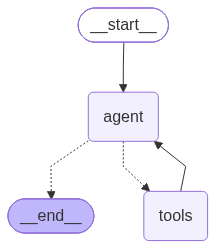

In [44]:
graph_builder = StateGraph(State)
graph_builder.add_node("agent", agent_node)
graph_builder.add_node("tools", tool_node)

graph_builder.add_edge(START, "agent") 

graph_builder.add_conditional_edges(
    "agent",
    should_continue,
    {
        "tools": "tools",
        END: END
    }
)

graph_builder.add_edge("tools", "agent") 
graph = graph_builder.compile()
graph

In [45]:
PR_NUMBER = 11

In [46]:
initial_state = {
    "messages": [
        HumanMessage(
            content=f"Review PR #{PR_NUMBER}"
        )
    ],
    "pr_number": PR_NUMBER,
    "verdict":   "",
}

result = graph.invoke(initial_state)

<Response [200]>


In [47]:
result

{'messages': [HumanMessage(content='Review PR #11', additional_kwargs={}, response_metadata={}, id='f5ecfd0f-4ae4-4395-bbe9-c72b75e6dc57'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 41, 'prompt_tokens': 192, 'total_tokens': 233, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_2f07e3a0e2', 'id': 'chatcmpl-EPHkJc5qv7Id8gOfrmdxfOfQYU56h', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a0b224-5d97-78b2-ab71-ecd34d9afeb8-0', tool_calls=[{'name': 'get_pr_details', 'args': {}, 'id': 'call_529524N4SFhLEAts6oZrcKqs', 'type': 'tool_call'}, {'name': 'get_pr_files', 'args': {}, 'id': 'call_AdfDvnSVA8lMYDR9Xo0NfpwI', 'type': 'tool_call'}],

In [48]:
final_review = result["messages"][-1].content
print(final_review)

## 🤖 CodeSentinel Review
### ✅ What looks good
- The PR is open and actively being worked on, which is a good sign of ongoing development and testing.

### ⚠️ Issues Found
- The PR title "I am testing my agent is working or not" is not descriptive of the changes made. It should be more specific to the changes or fixes implemented.
- The code change in `orders.py` still contains a hardcoded SQL query, which is vulnerable to SQL injection. The change from `id = 3123123` to `id = somethign bad` does not resolve the issue.
- The comment "here is my password : Rahul" is a security risk and should be removed immediately.
- The description "Seems I have some issue in my code." is vague and does not provide enough context about the purpose of the PR or the issues it aims to address.

### 🔧 Suggestions
- Update the PR title to reflect the specific changes or fixes being made.
- Replace the hardcoded SQL query with a parameterized query to prevent SQL injection.
- Remove any sensitive informatio